In [ ]:
afrom google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import zipfile
with zipfile.ZipFile('/content/drive/MyDrive/sentinel_watch/kaggle/archive (6).zip', 'r') as z:
    z.extractall('/content/kaggle_forest')
print("Done!")

Done!


In [ ]:
!pip install -U segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.1 MB/s eta 0:00:00


In [ ]:
# STEP 1: IMPORTS 
import os
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score
import rasterio

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


In [ ]:
# STEP 2: TRANSFORMS 
kaggle_transform = A.Compose([
    A.Resize(256, 256),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Normalize(),
    ToTensorV2()
], additional_targets={'image2': 'image'})

hotspot_transform = A.Compose([
    A.Resize(256, 256),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.RandomBrightnessContrast(p=0.3),
    A.Normalize(),
    ToTensorV2()
], additional_targets={'image2': 'image'}, is_check_shapes=False)

In [ ]:
# STEP 3: KAGGLE FOREST CHANGE DATASET
class ForestChangeDataset(Dataset):
    def __init__(self, df, img_dir, transform=None):
        self.df = df
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        folder = os.path.join(self.img_dir, row['dir'])
        img1 = np.array(Image.open(os.path.join(folder, row['img_1'])).convert('RGB'))
        img2 = np.array(Image.open(os.path.join(folder, row['img_2'])).convert('RGB'))
        label_path = row['label'].replace('\\', '/')
        mask = np.array(Image.open(os.path.join(self.img_dir, label_path)).convert('L'))
        mask = (mask > 127).astype(np.float32)
        if self.transform:
            aug = self.transform(image=img1, image2=img2, mask=mask)
            img1 = aug['image']
            img2 = aug['image2']
            mask = aug['mask'].unsqueeze(0)
        return img1, img2, mask

df = pd.read_csv('/content/kaggle_forest/train.csv')
kaggle_dataset = ForestChangeDataset(df, '/content/kaggle_forest/images', kaggle_transform)
print(f"Kaggle forest dataset: {len(kaggle_dataset)} samples")
b1, b2, m = next(iter(DataLoader(kaggle_dataset, batch_size=2)))
print(f"Shapes — img1: {b1.shape}, img2: {b2.shape}, mask: {m.shape}")

Kaggle forest dataset: 301 samples
Shapes — img1: torch.Size([2, 3, 256, 256]), img2: torch.Size([2, 3, 256, 256]), mask: torch.Size([2, 1, 256, 256])


In [ ]:


kaggle_loader = DataLoader(kaggle_dataset, batch_size=8, shuffle=True,
                           num_workers=2, pin_memory=True)
print(f"Pretrain dataset: {len(kaggle_dataset)} samples (Kaggle only)")

Pretrain dataset: 301 samples (Kaggle only)


In [ ]:

import torch.nn.functional as F

class CombinedLoss(nn.Module):
    def __init__(self, bce_weight=0.5, dice_weight=0.5, pos_weight=10.0):
        super().__init__()
        self.bce_weight  = bce_weight
        self.dice_weight = dice_weight
        self.dice        = smp.losses.DiceLoss(mode='binary')
       
        self.pos_weight  = torch.tensor([pos_weight])

    def forward(self, pred, mask):
        bce  = F.binary_cross_entropy(
            pred, mask,
            weight=None,
            reduction='none'
        )

        pw   = (mask * (self.pos_weight.to(pred.device) - 1) + 1)
        bce  = (bce * pw).mean()
        dice = self.dice(pred, mask)
        return self.bce_weight * bce + self.dice_weight * dice

criterion = CombinedLoss(bce_weight=0.5, dice_weight=0.5, pos_weight=10.0)
print("Combined loss ready (Dice + weighted BCE, pos_weight=10)")

Combined loss ready (Dice + weighted BCE, pos_weight=10)


In [ ]:
# STEP 5: HOTSPOT DATASET 
class HotspotDatasetAuto(Dataset):
    def __init__(self, npy_dir, transform=None):
        self.samples = []
        self.transform = transform

        hotspots = {}
        for f in sorted(os.listdir(npy_dir)):
            if not f.endswith('.npy'):
                continue
            parts = f.replace('_stack.npy', '').split('_')
            date_idx = next(i for i, p in enumerate(parts) if p.isdigit() and len(p)==8)
            hotspot_name = '_'.join(parts[:date_idx])
            date = parts[date_idx]
            if hotspot_name not in hotspots:
                hotspots[hotspot_name] = []
            hotspots[hotspot_name].append((date, os.path.join(npy_dir, f)))

        for hotspot_name, files in hotspots.items():
            files.sort(key=lambda x: x[0])
            for i in range(len(files) - 1):
                self.samples.append((files[i][1], files[i+1][1], hotspot_name))

        print(f"Found {len(self.samples)} hotspot pairs")

    def compute_ndvi(self, arr):
        b08 = arr[:, :, 3].astype(np.float32)
        b04 = arr[:, :, 2].astype(np.float32)
        denom = b08 + b04
        denom[denom == 0] = 1e-6
        return (b08 - b04) / denom

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        before_path, after_path, hotspot_name = self.samples[idx]
        before = np.load(before_path).astype(np.float32)
        after  = np.load(after_path).astype(np.float32)
        ndvi_b = self.compute_ndvi(before)
        ndvi_a = self.compute_ndvi(after)
        dndvi  = ndvi_b - ndvi_a
        mask   = (dndvi > 0.15).astype(np.float32)
        img1   = before[:, :, :6]
        img2   = after[:, :, :6]
        for img in [img1, img2]:
            for c in range(6):
                p2, p98 = np.percentile(img[:,:,c], 2), np.percentile(img[:,:,c], 98)
                img[:,:,c] = np.clip((img[:,:,c] - p2) / (p98 - p2 + 1e-6) * 255, 0, 255)
        img1 = img1.astype(np.uint8)
        img2 = img2.astype(np.uint8)
        if self.transform:
            aug  = self.transform(image=img1, image2=img2, mask=mask)
            img1 = aug['image']
            img2 = aug['image2']
            mask = aug['mask'].unsqueeze(0)
        return img1, img2, mask

hotspot_dataset = HotspotDatasetAuto(
    npy_dir='/content/drive/MyDrive/sentinel_watch/npy',
    transform=hotspot_transform
)
hotspot_loader = DataLoader(hotspot_dataset, batch_size=2, shuffle=True)
hb1, hb2, hm = next(iter(hotspot_loader))
print(f"Hotspot shapes — img1: {hb1.shape}, img2: {hb2.shape}, mask: {hm.shape}")

Found 90 hotspot pairs
Hotspot shapes — img1: torch.Size([2, 6, 256, 256]), img2: torch.Size([2, 6, 256, 256]), mask: torch.Size([2, 1, 256, 256])


In [ ]:
# STEP 6: MODELS
class SiameseUNet6(nn.Module):
    def __init__(self):
        super().__init__()
        self.unet = smp.Unet(
            encoder_name='resnet50',
            encoder_weights='imagenet',
            in_channels=6,
            classes=1,
            activation='sigmoid'
        )
    def forward(self, img1, img2):
        return self.unet(torch.cat([img1, img2], dim=1))

class SiameseUNet12(nn.Module):
    def __init__(self):
        super().__init__()
        self.unet = smp.Unet(
            encoder_name='resnet50',
            encoder_weights=None,
            in_channels=12,
            classes=1,
            activation='sigmoid'
        )
    def forward(self, img1, img2):
        return self.unet(torch.cat([img1, img2], dim=1))

pretrain_model = SiameseUNet6().to(device)
finetune_model = SiameseUNet12().to(device)
print("Models ready!")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

Models ready!


In [ ]:
# STEP 7: TRAINING FUNCTION
criterion = smp.losses.DiceLoss(mode='binary')

def train_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    for img1, img2, mask in loader:
        img1, img2, mask = img1.to(device), img2.to(device), mask.to(device)
        optimizer.zero_grad()
        loss = criterion(model(img1, img2), mask)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

Pretrain dataset: 301 samples (Kaggle only)

  STAGE 1: PRETRAINING ON KAGGLE FOREST DATA
Epoch 1/30 — Loss: 0.8605
  ✓ Best saved (0.8605)
Epoch 2/30 — Loss: 0.7727
  ✓ Best saved (0.7727)
Epoch 3/30 — Loss: 0.7324
  ✓ Best saved (0.7324)
Epoch 4/30 — Loss: 0.7138
  ✓ Best saved (0.7138)
Epoch 5/30 — Loss: 0.6976
  ✓ Best saved (0.6976)
  ✓ Checkpoint saved (epoch 5)
Epoch 6/30 — Loss: 0.6758
  ✓ Best saved (0.6758)
Epoch 7/30 — Loss: 0.6737
  ✓ Best saved (0.6737)
Epoch 8/30 — Loss: 0.6522
  ✓ Best saved (0.6522)
Epoch 9/30 — Loss: 0.6425
  ✓ Best saved (0.6425)
Epoch 10/30 — Loss: 0.6345
  ✓ Best saved (0.6345)
  ✓ Checkpoint saved (epoch 10)
Epoch 11/30 — Loss: 0.6250
  ✓ Best saved (0.6250)
Epoch 12/30 — Loss: 0.6158
  ✓ Best saved (0.6158)
Epoch 13/30 — Loss: 0.6092
  ✓ Best saved (0.6092)
Epoch 14/30 — Loss: 0.6062
  ✓ Best saved (0.6062)
Epoch 15/30 — Loss: 0.6011
  ✓ Best saved (0.6011)
  ✓ Checkpoint saved (epoch 15)
Epoch 16/30 — Loss: 0.5940
  ✓ Best saved (0.5940)
Epoch 17

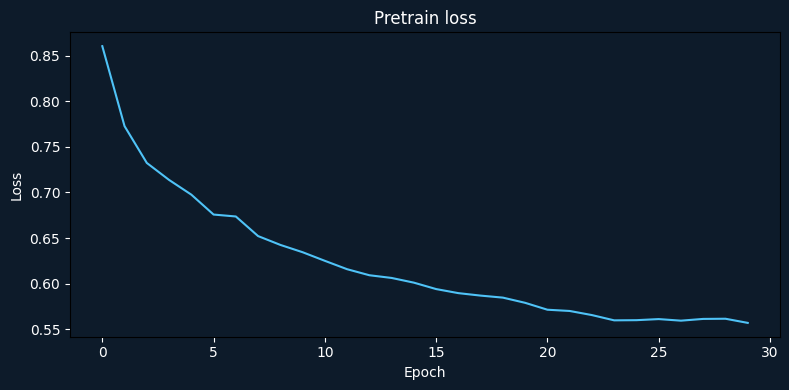

In [ ]:
# STEP 8: PRETRAIN ON KAGGLE ONLY 
import torch.nn.functional as F

class CombinedLoss(nn.Module):
    def __init__(self, bce_weight=0.5, dice_weight=0.5, pos_weight=10.0):
        super().__init__()
        self.bce_weight  = bce_weight
        self.dice_weight = dice_weight
        self.dice        = smp.losses.DiceLoss(mode='binary')
        self.pos_weight  = torch.tensor([pos_weight])

    def forward(self, pred, mask):
        bce = F.binary_cross_entropy(pred, mask, reduction='none')
        pw  = (mask * (self.pos_weight.to(pred.device) - 1) + 1)
        bce = (bce * pw).mean()
        return self.bce_weight * bce + self.dice_weight * self.dice(pred, mask)

criterion = CombinedLoss(bce_weight=0.5, dice_weight=0.5, pos_weight=10.0)

kaggle_loader = DataLoader(kaggle_dataset, batch_size=8, shuffle=True,
                           num_workers=2, pin_memory=True)
print(f"Pretrain dataset: {len(kaggle_dataset)} samples (Kaggle only)")

pretrain_model     = SiameseUNet6().to(device)
pretrain_optimizer = torch.optim.Adam(pretrain_model.parameters(), lr=1e-4)
scheduler_pretrain = torch.optim.lr_scheduler.CosineAnnealingLR(
                         pretrain_optimizer, T_max=30)

PRETRAIN_BEST = '/content/drive/MyDrive/sentinel_watch/pretrain_best.pt'
PRETRAIN_CKPT = '/content/drive/MyDrive/sentinel_watch/pretrain_latest.pt'
SAVE_EVERY    = 5

best_pretrain_loss = float('inf')
start_epoch        = 0
pretrain_losses    = []

if os.path.exists(PRETRAIN_CKPT):
    ckpt = torch.load(PRETRAIN_CKPT, map_location=device)
    pretrain_model.load_state_dict(ckpt['model_state'])
    pretrain_optimizer.load_state_dict(ckpt['optim_state'])
    start_epoch     = ckpt['epoch']
    pretrain_losses = ckpt['loss_history']
    best_pretrain_loss = min(pretrain_losses)
    for _ in range(start_epoch):
        scheduler_pretrain.step()
    print(f"Resumed from epoch {start_epoch}")

print("\n" + "="*50)
print("  STAGE 1: PRETRAINING ON KAGGLE FOREST DATA")
print("="*50)

for epoch in range(start_epoch, 30):
    pretrain_model.train()
    total_loss = 0
    for img1, img2, mask in kaggle_loader:
        img1, img2, mask = img1.to(device), img2.to(device), mask.to(device)
        pretrain_optimizer.zero_grad()
        pred = pretrain_model(img1, img2)
        loss = criterion(pred, mask)
        loss.backward()
        pretrain_optimizer.step()
        total_loss += loss.item()

    epoch_loss = total_loss / len(kaggle_loader)
    scheduler_pretrain.step()
    pretrain_losses.append(epoch_loss)
    print(f"Epoch {epoch+1}/30 — Loss: {epoch_loss:.4f}")

    if epoch_loss < best_pretrain_loss:
        best_pretrain_loss = epoch_loss
        torch.save({
            'epoch':        epoch + 1,
            'model_state':  pretrain_model.state_dict(),
            'optim_state':  pretrain_optimizer.state_dict(),
            'loss':         epoch_loss,
            'loss_history': pretrain_losses,
        }, PRETRAIN_BEST)
        print(f"  ✓ Best saved ({epoch_loss:.4f})")

    if (epoch + 1) % SAVE_EVERY == 0:
        torch.save({
            'epoch':        epoch + 1,
            'model_state':  pretrain_model.state_dict(),
            'optim_state':  pretrain_optimizer.state_dict(),
            'loss':         epoch_loss,
            'loss_history': pretrain_losses,
        }, PRETRAIN_CKPT)
        print(f"  ✓ Checkpoint saved (epoch {epoch+1})")

print(f"\nBest pretrain loss: {best_pretrain_loss:.4f} — Saved!")


BG = '#0D1B2A'
plt.figure(figsize=(8, 4))
plt.plot(pretrain_losses, color='#4FC3F7', linewidth=1.5)
plt.title('Pretrain loss', color='white')
plt.xlabel('Epoch', color='white')
plt.ylabel('Loss', color='white')
plt.gca().set_facecolor(BG)
plt.gcf().patch.set_facecolor(BG)
plt.tick_params(colors='white')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/sentinel_watch/pretrain_loss.png', dpi=150, facecolor=BG)
plt.show()

In [ ]:

pretrain_ckpt = torch.load(PRETRAIN_BEST, map_location=device)
pretrain_state = pretrain_ckpt['model_state']

finetune_state = finetune_model.state_dict()

transferred = 0
skipped = 0
for k, v in pretrain_state.items():
    # Skip first conv layer (different input channels 6 vs 12)
    if 'encoder.layer0' in k or 'encoder.conv1' in k:
        skipped += 1
        continue
    if k in finetune_state and finetune_state[k].shape == v.shape:
        finetune_state[k] = v
        transferred += 1
    else:
        skipped += 1

finetune_model.load_state_dict(finetune_state)
print(f"Transferred: {transferred} layers, Skipped: {skipped} layers")

Transferred: 379 layers, Skipped: 1 layers


In [ ]:

finetune_model = SiameseUNet12().to(device)

# Transfer weights again fresh
pretrain_ckpt  = torch.load(PRETRAIN_BEST, map_location=device)
pretrain_state = pretrain_ckpt['model_state']
finetune_state = finetune_model.state_dict()

transferred = 0
for k, v in pretrain_state.items():
    if 'encoder.layer0' in k or 'encoder.conv1' in k:
        continue
    if k in finetune_state and finetune_state[k].shape == v.shape:
        finetune_state[k] = v
        transferred += 1

finetune_model.load_state_dict(finetune_state)
print(f"Transferred {transferred} layers")

# First conv gets 10x higher LR to adapt fast to 12ch input
first_conv_params      = [p for n, p in finetune_model.named_parameters()
                          if 'encoder.layer0' in n or 'encoder.conv1' in n]
rest_params            = [p for n, p in finetune_model.named_parameters()
                          if 'encoder.layer0' not in n and 'encoder.conv1' not in n]

finetune_optimizer = torch.optim.Adam([
    {'params': first_conv_params, 'lr': 1e-3},   # high LR for new first conv
    {'params': rest_params,       'lr': 1e-5},    # low LR to preserve transfer
], lr=1e-5)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(finetune_optimizer, T_max=100)
print("Layer-wise LR ready — first conv: 1e-3, rest: 1e-5")

Transferred 379 layers
Layer-wise LR ready — first conv: 1e-3, rest: 1e-5


Transferred 379 layers

  STAGE 2: FINETUNING ON HOTSPOT DATA (12 BANDS)
Epoch 1/100 — Loss: 0.8028  LR: 1.00e-04
  ✓ Best saved (0.8028)
Epoch 2/100 — Loss: 0.7040  LR: 1.00e-04
  ✓ Best saved (0.7040)
Epoch 3/100 — Loss: 0.6866  LR: 1.00e-04
  ✓ Best saved (0.6866)
Epoch 4/100 — Loss: 0.6910  LR: 1.00e-04
  No improve 1/15
Epoch 5/100 — Loss: 0.6818  LR: 1.00e-04
  ✓ Best saved (0.6818)
Epoch 6/100 — Loss: 0.6466  LR: 1.00e-04
  ✓ Best saved (0.6466)
Epoch 7/100 — Loss: 0.6339  LR: 1.00e-04
  ✓ Best saved (0.6339)
Epoch 8/100 — Loss: 0.6217  LR: 1.00e-04
  ✓ Best saved (0.6217)
Epoch 9/100 — Loss: 0.6577  LR: 1.00e-04
  No improve 1/15
Epoch 10/100 — Loss: 0.6303  LR: 1.00e-04
  No improve 2/15
  ✓ Checkpoint saved (epoch 10)
Epoch 11/100 — Loss: 0.6115  LR: 1.00e-04
  ✓ Best saved (0.6115)
Epoch 12/100 — Loss: 0.6274  LR: 1.00e-04
  No improve 1/15
Epoch 13/100 — Loss: 0.6104  LR: 1.00e-04
  ✓ Best saved (0.6104)
Epoch 14/100 — Loss: 0.6362  LR: 1.00e-04
  No improve 1/15
Epoch 15/1

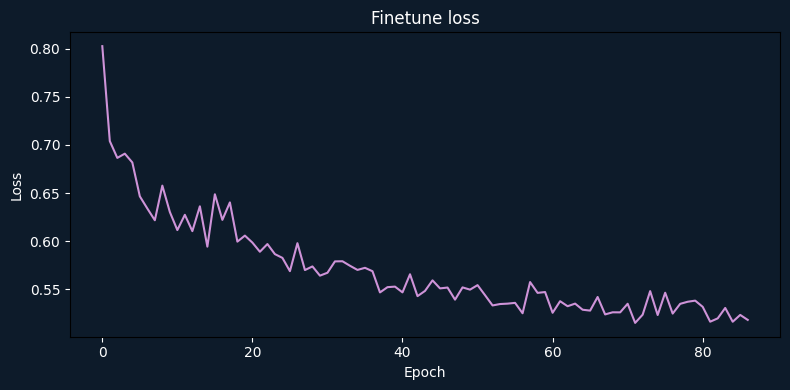

In [ ]:

finetune_model = SiameseUNet12().to(device)
pretrain_ckpt  = torch.load(PRETRAIN_BEST, map_location=device)
pretrain_state = pretrain_ckpt['model_state']
finetune_state = finetune_model.state_dict()

transferred = 0
for k, v in pretrain_state.items():
    if 'encoder.layer0' in k or 'encoder.conv1' in k:
        continue
    if k in finetune_state and finetune_state[k].shape == v.shape:
        finetune_state[k] = v
        transferred += 1

finetune_model.load_state_dict(finetune_state)
print(f"Transferred {transferred} layers")


first_conv_params = [p for n, p in finetune_model.named_parameters()
                     if 'encoder.layer0' in n or 'encoder.conv1' in n]
rest_params       = [p for n, p in finetune_model.named_parameters()
                     if 'encoder.layer0' not in n and 'encoder.conv1' not in n]

finetune_optimizer = torch.optim.Adam([
    {'params': first_conv_params, 'lr': 1e-4},
    {'params': rest_params,       'lr': 1e-4},
], lr=1e-4)


scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    finetune_optimizer, mode='min', factor=0.5,
    patience=5, min_lr=1e-7
)

criterion = CombinedLoss(bce_weight=0.5, dice_weight=0.5, pos_weight=3.0)

FINETUNE_BEST   = '/content/drive/MyDrive/sentinel_watch/finetune_best.pt'
FINETUNE_CKPT   = '/content/drive/MyDrive/sentinel_watch/finetune_latest.pt'
SAVE_EVERY      = 10
EARLY_STOP      = 15

best_loss       = float('inf')
finetune_losses = []
no_improve      = 0

print("\n" + "="*50)
print("  STAGE 2: FINETUNING ON HOTSPOT DATA (12 BANDS)")
print("="*50)

for epoch in range(100):
    finetune_model.train()
    total_loss = 0
    for img1, img2, mask in hotspot_loader:
        img1, img2, mask = img1.to(device), img2.to(device), mask.to(device)
        finetune_optimizer.zero_grad()
        pred = finetune_model(img1, img2)
        loss = criterion(pred, mask)
        loss.backward()
        finetune_optimizer.step()
        total_loss += loss.item()

    epoch_loss = total_loss / len(hotspot_loader)
    finetune_losses.append(epoch_loss)
    scheduler.step(epoch_loss)

    # Print current LR
    current_lr = finetune_optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch+1}/100 — Loss: {epoch_loss:.4f}  LR: {current_lr:.2e}")

    if epoch_loss < best_loss:
        best_loss  = epoch_loss
        no_improve = 0
        torch.save({
            'epoch':        epoch + 1,
            'model_state':  finetune_model.state_dict(),
            'optim_state':  finetune_optimizer.state_dict(),
            'loss':         epoch_loss,
            'loss_history': finetune_losses,
        }, FINETUNE_BEST)
        print(f"  ✓ Best saved ({epoch_loss:.4f})")
    else:
        no_improve += 1
        print(f"  No improve {no_improve}/{EARLY_STOP}")

    if (epoch + 1) % SAVE_EVERY == 0:
        torch.save({
            'epoch':        epoch + 1,
            'model_state':  finetune_model.state_dict(),
            'optim_state':  finetune_optimizer.state_dict(),
            'loss':         epoch_loss,
            'loss_history': finetune_losses,
        }, FINETUNE_CKPT)
        print(f"  ✓ Checkpoint saved (epoch {epoch+1})")

    if no_improve >= EARLY_STOP:
        print(f"\nEarly stopping at epoch {epoch+1} — no improvement for {EARLY_STOP} epochs")
        break

print(f"\nBest finetune loss: {best_loss:.4f} — Saved!")


BG = '#0D1B2A'
plt.figure(figsize=(8, 4))
plt.plot(finetune_losses, color='#CE93D8', linewidth=1.5)
plt.title('Finetune loss', color='white')
plt.xlabel('Epoch', color='white')
plt.ylabel('Loss', color='white')
plt.gca().set_facecolor(BG)
plt.gcf().patch.set_facecolor(BG)
plt.tick_params(colors='white')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/sentinel_watch/finetune_loss.png', dpi=150, facecolor=BG)
plt.show()

In [ ]:
# STEP 10: EVALUATE 
print("\n" + "="*50)
print("  STAGE 3: EVALUATION")
print("="*50)

finetune_model.load_state_dict(
    torch.load(FINETUNE_BEST, map_location=device)['model_state'])
finetune_model.eval()

all_preds = []
all_masks = []

with torch.no_grad():
    for img1, img2, mask in hotspot_loader:
        img1, img2 = img1.to(device), img2.to(device)
        pred = finetune_model(img1, img2).cpu()
        all_preds.append((pred > 0.5).float().numpy().flatten())
        all_masks.append(mask.numpy().flatten())

all_preds = np.concatenate(all_preds)
all_masks  = np.concatenate(all_masks)

f1   = f1_score(all_masks, all_preds, zero_division=0)
prec = precision_score(all_masks, all_preds, zero_division=0)
rec  = recall_score(all_masks, all_preds, zero_division=0)

print(f"  Precision : {prec:.3f}")
print(f"  Recall    : {rec:.3f}")
print(f"  F1 Score  : {f1:.3f}")

# ── Confusion matrix breakdown ────────────────────────────
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(all_masks, all_preds).ravel()
total = len(all_masks)
print(f"\n  TP: {tp:,}  FP: {fp:,}")
print(f"  TN: {tn:,}  FN: {fn:,}")
print(f"  Accuracy : {(tp+tn)/total:.3f}")
print(f"  IoU      : {tp/(tp+fp+fn):.3f}")


  STAGE 3: EVALUATION
  Precision : 0.716
  Recall    : 0.750
  F1 Score  : 0.733

  TP: 462,158  FP: 183,188
  TN: 5,099,201  FN: 153,693
  Accuracy : 0.943
  IoU      : 0.578


In [ ]:
# STEP 11: VISUALIZE
BG = '#0D1B2A'
fig, axes = plt.subplots(4, 4, figsize=(16, 16))
fig.patch.set_facecolor(BG)

with torch.no_grad():
    for i, (img1, img2, mask) in enumerate(hotspot_loader):
        if i >= 4: break
        img1, img2 = img1.to(device), img2.to(device)
        pred = finetune_model(img1, img2).cpu()

        im1 = img1[0].cpu().permute(1,2,0).numpy()[:,:,:3]
        im2 = img2[0].cpu().permute(1,2,0).numpy()[:,:,:3]
        im1 = (im1 - im1.min()) / (im1.max() - im1.min() + 1e-6)
        im2 = (im2 - im2.min()) / (im2.max() - im2.min() + 1e-6)

        axes[i][0].imshow(im1)
        axes[i][0].set_title('Before', color='white')
        axes[i][1].imshow(im2)
        axes[i][1].set_title('After', color='white')
        axes[i][2].imshow(mask[0][0], cmap='RdYlGn_r')
        axes[i][2].set_title('Ground Truth (dNDVI)', color='white')
        axes[i][3].imshow(pred[0][0] > 0.5, cmap='RdYlGn_r')
        axes[i][3].set_title('CNN Prediction', color='white')
        for ax in axes[i]:
            ax.axis('off')
            ax.set_facecolor(BG)

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/sentinel_watch/evaluation_final.png',
            dpi=150, facecolor=BG)
plt.show()
print("\nDone! Evaluation saved to Drive!")

Output hidden; open in https://colab.research.google.com to view.